In [1]:
# Name: Snehal gulhane
# Roll No: 18
# Sec: c
# Aim : To perform an analysis of Ensemble technique

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)


In [4]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="Target")

print("Dataset Shape:", X.shape)
print("\nFirst 5 Rows:")
display(X.head())

print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target Classes:
['malignant' 'benign']


Missing Values: 0

Class Distribution:
Target
1    357
0    212
Name: count, dtype: int64


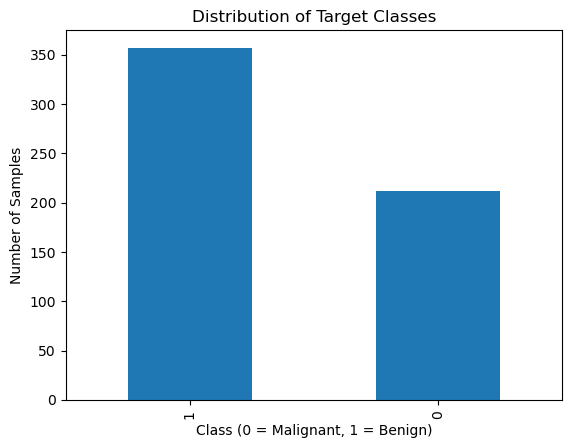

In [5]:
print("Missing Values:", X.isnull().sum().sum())
print("\nClass Distribution:")
print(y.value_counts())

y.value_counts().plot(kind="bar")
plt.title("Distribution of Target Classes")
plt.xlabel("Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [7]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("All models created successfully!")


All models created successfully!


In [8]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df.round(4))

Model Evaluation Results:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861
1,Decision Tree,0.9123,0.9559,0.9028,0.9286
2,Random Forest,0.9561,0.9589,0.9722,0.9655
3,Bagging,0.9386,0.9452,0.9583,0.9517
4,AdaBoost,0.9561,0.9467,0.9861,0.9660


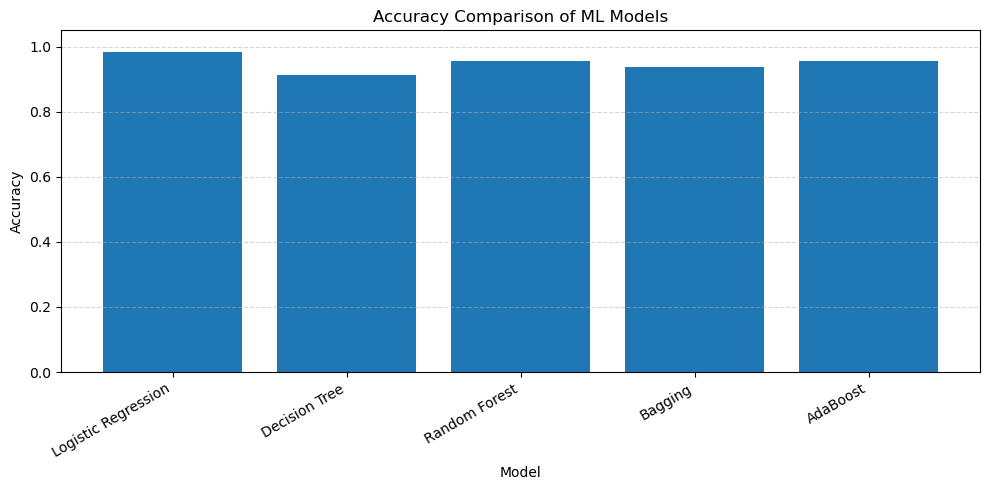

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Accuracy Comparison of ML Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

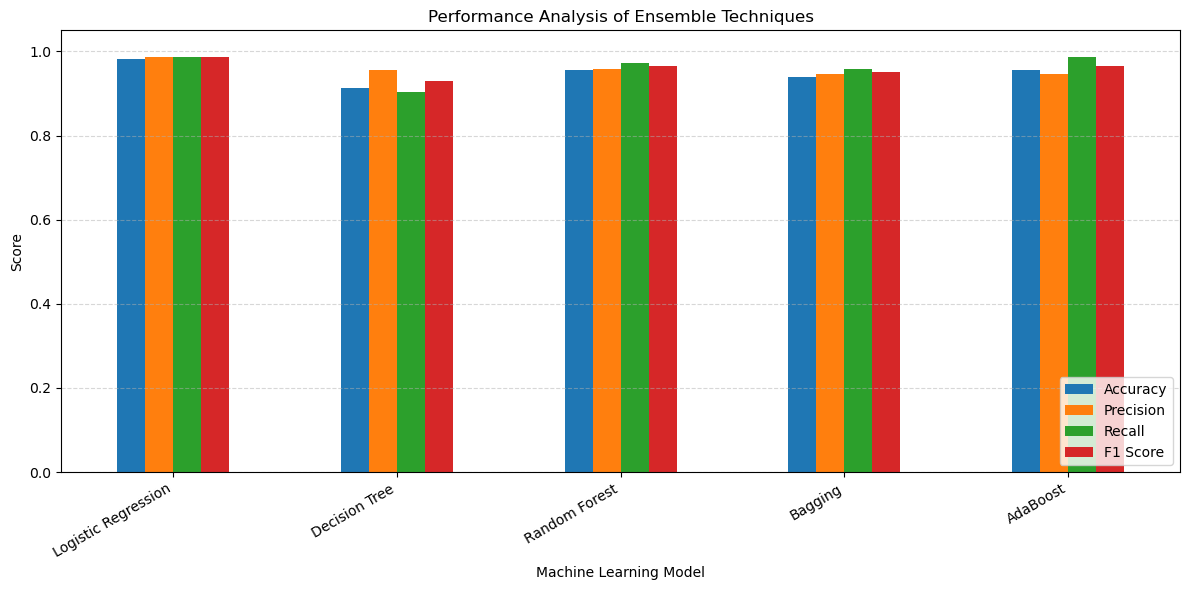

In [10]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Analysis of Ensemble Techniques")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

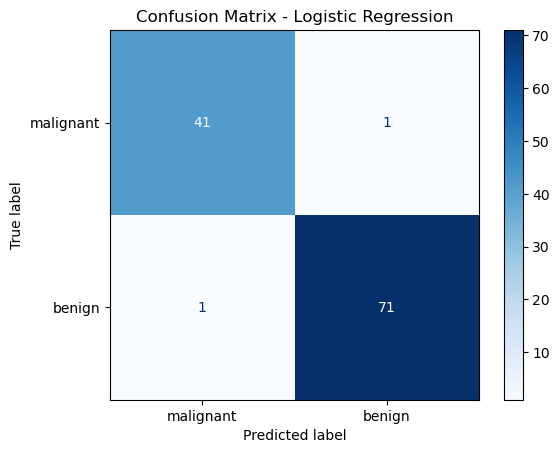

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [11]:
best_model_name = results_df.loc[
    results_df["Accuracy"].idxmax(), "Model"
]

best_model = models[best_model_name]
y_pred = predictions[best_model_name]

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=data.target_names,
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

In [12]:
best_row = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("ENSEMBLE TECHNIQUE ANALYSIS")
print("-" * 35)
print("Best Model:", best_row["Model"])
print("Accuracy:", round(best_row["Accuracy"] * 100, 2), "%")
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1 Score:", round(best_row["F1 Score"], 4))

print("\nConclusion:")
print(
    "The model with the highest test accuracy is",
    best_row["Model"]
)

ENSEMBLE TECHNIQUE ANALYSIS
-----------------------------------
Best Model: Logistic Regression
Accuracy: 98.25 %
Precision: 0.9861
Recall: 0.9861
F1 Score: 0.9861

Conclusion:
The model with the highest test accuracy is Logistic Regression


,Accuracy,Precision,Recall,F1 Score
Model,,,,
Random Forest,0.9561,0.9589,0.9722,0.9655
Bagging,0.9386,0.9452,0.9583,0.9517
AdaBoost,0.9561,0.9467,0.9861,0.9660


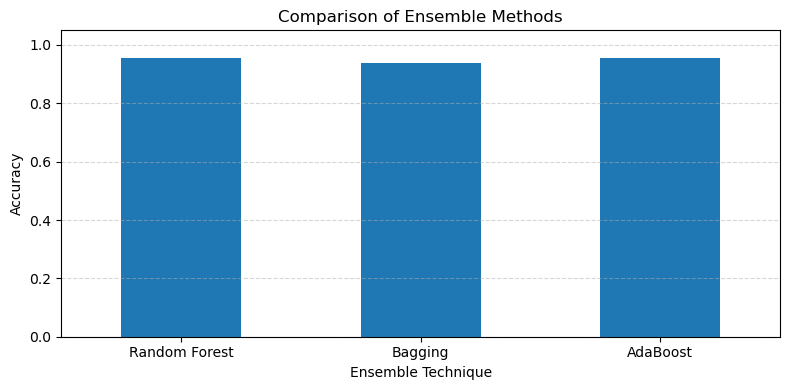

In [13]:
ensemble_names = ["Random Forest", "Bagging", "AdaBoost"]

ensemble_results = results_df[
    results_df["Model"].isin(ensemble_names)
].set_index("Model")

display(ensemble_results.round(4))

ensemble_results["Accuracy"].plot(
    kind="bar",
    figsize=(8, 4),
    title="Comparison of Ensemble Methods"
)

plt.xlabel("Ensemble Technique")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()